# Домашнє завдання №1 — аналітика (задача II, варіант S2)

## 0. Налаштування

In [7]:
import copy
import math
import os
import platform
import random
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from general import Student, load_students
from sorting import sort_builtin, sort_custom, save_students_csv

DATA_PATH = Path("data/students.csv")
RESULTS_PATH = Path("results/sort_results.csv")
FIG_DIR = Path("results/figures_sort")
FIG_DIR.mkdir(parents=True, exist_ok=True)

IMPLS = {
    "1: стандартне": sort_builtin,
    "2: власне": sort_custom,
}

## 1. Вступ і методологія

Алгоритм, який я реалізовувала, побудований на основі бінарного дерева пошуку. Тестувала на масивах розміром від 100 до 100 000 елементів. Для кожного розміру вимірювання запускалися по 5 разів, щоб взяти середнє арифметичне потім і мінімізувати похибку. Під час замірів фіксувався лише час побудови дерева та його in-order обходу, час на зчитування даних та запис у файл не вимірювався. Перед сортуванням вхідні дані перемішувалися (shuffling), для повної рандомності експерименту, бо в оригінальному файлі students вони посортовані.

## 2. Перевірка коректності (автотести) 

**Ідея.** Кожна реалізація отримує свою копію даних, а результат перевіряється чотирма способами:

1. довжина збігається;
2. рейтинги йдуть **за неспаданням** (`a[i] <= a[i+1]`);
3. склад студентів той самий (ніхто не втрачений і не задубльований; email унікальний);
4. рейтинги студентів не підмінені.

Порядок студентів з однаковим рейтингом за умовою не визначений, тому його не перевіряємо.

| Тест | Навіщо |
|---|---|
| `empty`, `single`, `two` | межові розміри |
| `already_sorted`, `reverse_sorted` | найгірші входи для наївного дерева |
| `all_equal`, `many_duplicates` | багато однакових ключів (рівні ключі теж можуть вироджувати дерево) |
| `boundaries` | рейтинги 0 і 100 та поряд з ними |
| `random` | випадкові дробові рейтинги |
| `deep_sorted`, `deep_equal` | 3000 елементів: ловить рекурсивну реалізацію (`RecursionError`) |
| `real_sample` | перші 5000 рядків справжнього файлу, у порядку файлу |
| `csv_roundtrip` | запис у CSV і зчитування назад дає ті самі студенти в тому ж порядку |

In [9]:
def mk(i, rating):
    return Student("Тест", "Тест", f"s{i}@student.org", 2000, 1, 1, "AAA-01", rating, "38(050)00-00-000")


def make_list(ratings):
    return [mk(i, r) for i, r in enumerate(ratings)]


def check_sorted(impl, students):
    """Повертає текст помилки або None."""
    expected = {s.m_email: s.m_rating for s in students}
    result = impl(copy.deepcopy(students))
    if result is None:
        return "функція повернула None: вона має ПОВЕРТАТИ відсортований список"
    if len(result) != len(students):
        return f"довжина {len(result)} замість {len(students)}"
    ratings = [s.m_rating for s in result]
    for i in range(len(ratings) - 1):
        if ratings[i] > ratings[i + 1]:
            return f"порушено порядок на позиції {i}: {ratings[i]} > {ratings[i + 1]}"
    if sorted(s.m_email for s in result) != sorted(expected):
        return "склад студентів змінився (втрачені або задубльовані записи)"
    for s in result:
        if expected[s.m_email] != s.m_rating:
            return f"у студента {s.m_email} підмінено рейтинг"
    return None


def t_empty(impl):            return check_sorted(impl, [])
def t_single(impl):           return check_sorted(impl, make_list([42.5]))
def t_two(impl):              return check_sorted(impl, make_list([70.0, 10.0]))
def t_already_sorted(impl):   return check_sorted(impl, make_list([i / 2 for i in range(200)]))
def t_reverse_sorted(impl):   return check_sorted(impl, make_list([i / 2 for i in range(199, -1, -1)]))
def t_all_equal(impl):        return check_sorted(impl, make_list([55.5] * 300))


def t_many_duplicates(impl):
    rng = random.Random(1)
    return check_sorted(impl, make_list([rng.choice([10.0, 20.0, 30.0]) for _ in range(500)]))


def t_boundaries(impl):
    return check_sorted(impl, make_list([0.0, 100.0, 0.0001, 99.9999, 0.0, 100.0, 50.0, 0.0, 100.0]))


def t_random(impl):
    rng = random.Random(2)
    return check_sorted(impl, make_list([round(rng.uniform(0, 100), 2) for _ in range(1000)]))


def t_deep_sorted(impl):
    return check_sorted(impl, make_list([i * 100 / 3000 for i in range(3000)]))


def t_deep_equal(impl):
    return check_sorted(impl, make_list([77.7] * 3000))


def t_real_sample(impl):
    return check_sorted(impl, load_students(DATA_PATH)[:5000])


def t_csv_roundtrip(impl):
    rng = random.Random(3)
    students = make_list([round(rng.uniform(0, 100), 1) for _ in range(200)])
    result = impl(copy.deepcopy(students))
    path = RESULTS_PATH.parent / "_tmp_sorted_test.csv"
    save_students_csv(result, path)
    back = load_students(path)
    path.unlink(missing_ok=True)
    if len(back) != len(result):
        return f"у файл записано {len(back)} рядків замість {len(result)}"
    for i, (a, b) in enumerate(zip(result, back)):
        for field in vars(a):
            x, y = getattr(a, field), getattr(b, field)
            same = math.isclose(x, y, rel_tol=1e-9) if isinstance(x, float) else x == y
            if not same:
                return f"рядок {i}, поле {field}: у пам'яті {x!r}, з файлу {y!r}"
    return None

TESTS = {
    "empty": t_empty, "single": t_single, "two": t_two,
    "already_sorted": t_already_sorted, "reverse_sorted": t_reverse_sorted,
    "all_equal": t_all_equal, "many_duplicates": t_many_duplicates,
    "boundaries": t_boundaries, "random": t_random,
    "deep_sorted": t_deep_sorted, "deep_equal": t_deep_equal,
    "real_sample": t_real_sample, "csv_roundtrip": t_csv_roundtrip,
}

def run_all_tests():
    table, details = {}, []
    for tname, tfn in TESTS.items():
        table[tname] = {}
        for iname, impl in IMPLS.items():
            try:
                problem = tfn(impl)
            except RecursionError:
                problem = "RecursionError: рекурсія занадто глибока (дерево вироджується в ланцюжок?)"
            except Exception as exc:   # помилка в самій реалізації теж є провалом тесту
                problem = f"виняток {type(exc).__name__}: {exc}"
            table[tname][iname] = "✅" if not problem else "❌"
            if problem:
                details.append(f"[{iname}] {tname}: {problem}")
    return pd.DataFrame(table).T, details


test_table, test_details = run_all_tests()
display(test_table)
print("\n".join(test_details) if test_details else "Усі тести пройдено.")

,1: стандартне,2: власне
empty,✅,✅
single,✅,✅
two,✅,✅
already_sorted,✅,✅
reverse_sorted,✅,✅
all_equal,✅,✅
many_duplicates,✅,✅
boundaries,✅,✅
random,✅,✅
deep_sorted,✅,✅


Усі тести пройдено.


**Висновок про коректність**

Усі тести пройшли успішно.

## 3. Вимірювання 

| колонка | що це |
|---|---|
| `impl` | назва реалізації, **точно** як ключ у `IMPLS` |
| `n` | кількість студентів |
| `repeat` | номер повторення (1, 2, 3, ...) |
| `time_s` | час сортування в секундах (без запису у файл) |

**Вимоги до вимірювання:**

- розміри від 100 до 100 000 (наприклад ті самі 10, що й у задачі I), ≥5 повторів на точку;
- на кожен запуск свіжа копія даних (`copy.deepcopy`) і той самий вхід для обох реалізацій у межах повтору;
- таймер `time.perf_counter()`, у вимір входить усе, що потрібно для побудови результату (дерево, відра, обхід);
- **порядок входу має значення**: у файлі студенти впорядковані за групою й рейтингом. Подумай, що це робить з деревом без балансування, і вирішіть, чи перемішувати вхід (з фіксованим seed) та поясни це в методології.

In [ ]:
def run_one(impl_name, students, repeat):
    data = copy.deepcopy(students)
    impl_func = IMPLS[impl_name]

    start_time = time.perf_counter()
    _ = impl_func(data)
    end_time = time.perf_counter()
    return {
        "impl": impl_name,
        "n": len(students),
        "repeat": repeat,
        "time_s": end_time - start_time
    }

def run_all_experiments():
    target_sizes = [100, 250, 500, 1000, 2500, 5000, 10000, 25000, 50000, 100000]
    repeats = 5
    results = []

    all_students = load_students(DATA_PATH)
    max_n = len(all_students)

    sizes = [n for n in target_sizes if n <= max_n]
    if max_n not in sizes and max_n > 100:
        sizes.append(max_n)

    for n in sizes:
        sample = all_students[:n]
        rng = random.Random(42)
        rng.shuffle(sample)
        for repeat in range(1, repeats + 1):
            for impl_name in IMPLS:
                res = run_one(impl_name, sample, repeat)
                results.append(res)

    return pd.DataFrame(results)

In [11]:
df_new = run_all_experiments()
RESULTS_PATH.parent.mkdir(exist_ok=True)
df_new.to_csv(RESULTS_PATH, index=False)

## 4. Завантаження результатів 

In [12]:
REQUIRED = ["impl", "n", "repeat", "time_s"]

if not RESULTS_PATH.exists():
    raise FileNotFoundError(f"Немає файлу {RESULTS_PATH}. Спочатку виконай розділ 3 і збережи результати.")

df = pd.read_csv(RESULTS_PATH)
missing = [c for c in REQUIRED if c not in df.columns]
assert not missing, f"У файлі бракує колонок: {missing}"

order = [a for a in IMPLS if a in df["impl"].unique()]
unknown = set(df["impl"].unique()) - set(IMPLS)
assert not unknown, f"У файлі є назви, яких немає в IMPLS: {unknown}"
COLORS = dict(zip(order, ["#4C78A8", "#F58518"]))

reps = df.groupby(["impl", "n"]).size()
if reps.min() < 5:
    print("⚠️ Є точки, де менше 5 повторень:", reps[reps < 5].to_dict())
print(f"Рядків: {len(df)}; реалізації: {order}")
print("Розміри:", sorted(df["n"].unique().tolist()))

Рядків: 100; реалізації: ['1: стандартне', '2: власне']
Розміри: [100, 250, 500, 1000, 2500, 5000, 10000, 25000, 50000, 100000]


## 5. Графіки 

In [13]:
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})


def stats(data, value_col="time_s", by=("impl", "n")):
    """Середнє, середньоквадратичне відхилення (вибіркове, ddof=1) і кількість повторень."""
    out = data.groupby(list(by))[value_col].agg(["mean", "std", "count"]).reset_index()
    out["std"] = out["std"].fillna(0.0)
    return out


def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200)
    plt.show()


S = stats(df)

### 5.1 Час сортування залежно від n

Ліворуч лінійні осі, праворуч log–log. У подвійній логарифмічній шкалі степенева залежність T ~ nᵏ виглядає **прямою з нахилом k**: нахил ≈ 1 це n або n·log n, ≈ 2 це n².

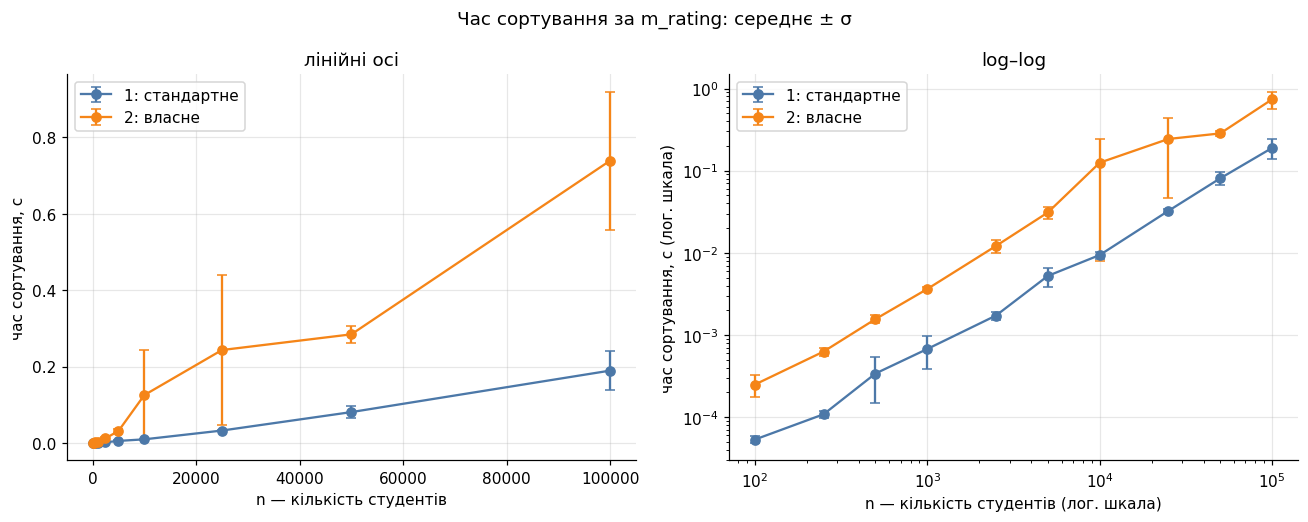

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, log in zip(axes, (False, True)):
    for a in order:
        s = S[S["impl"] == a]
        ax.errorbar(s["n"], s["mean"], yerr=s["std"], marker="o", capsize=3, label=a, color=COLORS[a])
    if log:
        ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("n — кількість студентів" + (" (лог. шкала)" if log else ""))
    ax.set_ylabel("час сортування, с" + (" (лог. шкала)" if log else ""))
    ax.set_title("log–log" if log else "лінійні осі")
    ax.legend()
fig.suptitle("Час сортування за m_rating: середнє ± σ")
save_fig("S2_1_time_vs_n")

**Аналіз**

Моя функція сортування значно повільніша за вбудовану функцію сортування: на максимальних даних, 100000 операцій, моє сортування приблизно в 4-5 разів повільніше за вбудовану. Також для вбудованого алгоритму час виконання майже стабільний між різними запусками, а у дерева пошуку розкид часу помітно більший. 

### 5.2 У скільки разів власне сортування повільніше (або швидше) за стандартне

Значення > 1 означає, що власне сортування повільніше за стандартне. Лінія близько до горизонталі означає однакову асимптотику, зростання лінії означає, що власне сортування гірше масштабується.

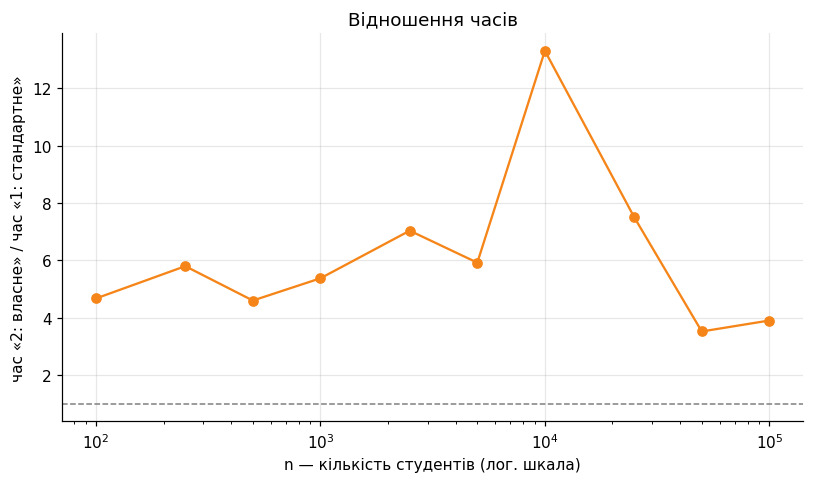

In [15]:
base, other = order[0], order[-1]
a = S[S["impl"] == base].set_index("n")["mean"]
b = S[S["impl"] == other].set_index("n")["mean"]
ratio = (b / a).dropna()

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(ratio.index, ratio.values, marker="o", color=COLORS[other])
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xlabel("n — кількість студентів (лог. шкала)")
ax.set_ylabel(f"час «{other}» / час «{base}»")
ax.set_title("Відношення часів")
save_fig("S2_2_ratio")

**Аналіз**

Крива відношення часів загалом зі збільшенням кількості елементів n є сталою.Причина: складність обох nlog n, тобто часи сортування = T = cnlog n, тобто вони відрізняються тільки константою с, їхнє відношення і мало би бути на графіку в теорії

### 5.3 Таблиця результатів і нахил у log–log

Нахил = коефіцієнт прямої `log T ≈ k·log n + b`, знайдений методом найменших квадратів по середніх. Орієнтир: n·log n на діапазоні 100…100 000 дає k ≈ 1.1–1.2, n² дає k ≈ 2.

In [16]:
table = S.copy()
table["час, мс (середнє ± σ)"] = [f"{m * 1000:.3f} ± {s * 1000:.3f}" for m, s in zip(table["mean"], table["std"])]
pivot = table.pivot(index="n", columns="impl", values="час, мс (середнє ± σ)")[order]
display(pivot)

slopes = {}
for a in order:
    s = S[(S["impl"] == a) & (S["mean"] > 0)]
    slopes[a] = np.polyfit(np.log(s["n"]), np.log(s["mean"]), 1)[0]
display(pd.DataFrame({"нахил k у log–log": slopes}).round(2))

impl,1: стандартне,2: власне
n,,
100,0.053 ± 0.005,0.250 ± 0.076
250,0.108 ± 0.012,0.629 ± 0.075
500,0.340 ± 0.193,1.563 ± 0.170
1000,0.677 ± 0.286,3.637 ± 0.220
2500,1.725 ± 0.196,12.134 ± 2.208
5000,5.241 ± 1.383,31.020 ± 4.859
10000,9.414 ± 0.932,125.219 ± 117.350
25000,32.415 ± 1.967,243.223 ± 197.132
50000,80.748 ± 14.712,284.341 ± 22.686


,нахил k у log–log
1: стандартне,1.2
2: власне,1.2


**Аналіз**

Обидва нахили приблизно = 1.2, що відповідає nlog n, а не n² (який дав би 2). Це підтверджує, що для випадкових даних BST працює за середню складність O(nlog n).

## 6. Висновки

На найбільшій кількості даних, вбудована реалізація значно (в 4-5 разів) швидша за мою. Ми підтвердили, що за умови випадкових даних наше сортування працює зі складністю $O(n \log n)$, що загалом характерно для бінарних дерев пошуку. Обмеження: тестування проводилось на одному інтерпретаторі, на попередньо перемішаних даних і сортуванням лише за одним параметром (рейтингом). З мінусів: DoS атака цілком імовірно таки зламає алгоритм, якщо подати список студентів як уже відсортований масив. Тоді наше дерево просто виродиться у зв'язний масив і швидкість пошуку різко впаде до  $O(n^2)$, а якщо дати надзвичайно великий відсортований масив, то в нас може статися переповнення стеку рекурсії, і програма впаде.